#### Série: DuckDB Masterclass
**Ordem sugerida de leitura:** 3 de 14


📚 **Material de apoio — Laboratórios práticos no Jupyter Notebook**

Acompanhe os conceitos deste artigo com exemplos SQL, exercícios e laboratórios da DuckDB Masterclass.

🔗 [Acessar os laboratórios no GitHub](https://github.com/aestevaomoraes/duckdb-masterclass)

# DuckDB Masterclass — Capítulo 03
## Tipos aninhados: `LIST`, `STRUCT`, `MAP` e `JSON` nativo

**Edição-piloto para autoaprendizagem e publicação** · [Laboratórios no GitHub](https://github.com/aestevaomoraes/duckdb-masterclass)

**Público:** pessoas com SQL intermediário que desejam modelar dados semiestruturados no DuckDB.

**Como estudar:** leia a hipótese → execute a célula → confira a validação → interprete os resultados. Os registros são **inteiramente sintéticos**; não há credenciais nem caminhos pessoais.

**Pré-requisitos:** Python, Jupyter, DuckDB e Pandas. Execute o notebook de cima para baixo em kernel reiniciado.

## 03.1 — Objetivos e diagnóstico

Ao final você deverá ser capaz de: distinguir os quatro tipos; selecionar campos de `STRUCT`; agregar e expandir `LIST`; consultar chaves de `MAP`; extrair propriedades de JSON; e escolher um tipo adequado a uma necessidade operacional.

**Pergunta diagnóstica:** como representar três medições de latência de um equipamento, sua localização e atributos variáveis, sem transformar tudo em uma única string?

## 03.2 — Modelo mental

| Tipo | Pergunta que responde | Exemplo de operação |
|---|---|---|
| `STRUCT` | Quais atributos *fixos* pertencem ao mesmo registro? | `local.cidade` |
| `LIST` | Quais valores se repetem dentro de uma linha? | `list_sum(latencias)` |
| `MAP` | Quais atributos são pares chave–valor tipados? | `map_extract_value(tags, 'prioridade')` |
| `JSON` | Como ler um documento semiestruturado? | `json_extract_string(payload, '$.modelo')` |

**Importante:** JSON é flexível, mas não substitui automaticamente os tipos aninhados tipados; conversões e campos ausentes precisam de tratamento.

### 🗺️ Anatomia de um equipamento

```text
Equipamento 101
├── local: STRUCT {cidade: 'Campo Grande', uf: 'MS'}
├── latencias: LIST [10, 20, 30]
├── tags: MAP {'prioridade': 'alta', 'ambiente': 'campo'}
└── payload: JSON {"modelo":"OLT-X","portas":8}
```

Cada estrutura atende a um padrão de acesso diferente. A imagem mental é a de um registro com campos tipados, não de uma string única.

## 03.3 — Preparação reproduzível

Não há download de dados ou instalação automática. Caso o import falhe, instale `duckdb` e `pandas` no ambiente do kernel antes de reexecutar.

In [7]:
import duckdb
from IPython.display import display

print("DuckDB:", duckdb.__version__)
con = duckdb.connect(":memory:")


DuckDB: 2.0.0


## 03.4 — Laboratório A: `STRUCT` e `LIST`

**Cenário:** uma equipe analisa latências de dois equipamentos por município.

**Hipótese:** acessar `local.cidade` não exige uma tabela separada; cada `LIST` pode ser agregada dentro do registro.

In [8]:
con.execute("""
CREATE TABLE equipamentos AS
SELECT 101 AS id,
       {'cidade': 'Campo Grande', 'uf': 'MS'} AS local,
       [10,20,30] AS latencias
UNION ALL
SELECT 102, {'cidade': 'Dourados', 'uf': 'MS'}, [15,25]
""")

res_estruturas = con.execute("""
SELECT id, local.cidade AS cidade,
       list_sum(latencias) AS soma_latencias,
       len(latencias) AS qtd_medicoes
FROM equipamentos ORDER BY id
""").df()
display(res_estruturas)
assert res_estruturas['soma_latencias'].tolist() == [60, 40]
assert res_estruturas['qtd_medicoes'].tolist() == [3, 2]


,id,cidade,soma_latencias,qtd_medicoes
0,101,Campo Grande,60.0,3
1,102,Dourados,40.0,2


**Interpretação:** a soma das medições por equipamento é 60 e 40. Essa operação não calcula automaticamente a média por cidade; a granularidade permanece **uma linha por equipamento**.


#### 🧠 Entendendo o código — STRUCT e LIST

Neste laboratório, utilizamos **tipos de dados aninhados** para armazenar e consultar informações de equipamentos de telecomunicações.

#### 1. STRUCT — Acessando atributos

```sql
local.cidade AS cidade
```

A coluna `local` contém uma estrutura com os atributos `cidade` e `uf`.

O operador `.` permite acessar diretamente o atributo desejado, sem necessidade de uma tabela adicional.

#### 2. LIST — Somando medições

```sql
list_sum(latencias) AS soma_latencias
```

A função `list_sum()` soma os valores armazenados na lista de cada equipamento.

- Equipamento 101: `10 + 20 + 30 = 60`
- Equipamento 102: `15 + 25 = 40`

#### 3. len() — Contando elementos

```sql
len(latencias) AS qtd_medicoes
```

Retorna a quantidade de medições presentes em cada lista.

#### 4. .df() e display() — Apresentando resultados

```python
res_estruturas = con.execute(sql).df()
display(res_estruturas)
```

O método `.df()` converte o resultado da consulta SQL em um DataFrame Pandas. A função `display()` apresenta esse resultado em formato tabular no Jupyter.

No código do laboratório, `sql` corresponde à consulta SQL executada; ela foi escrita diretamente dentro de `con.execute()`.

#### 5. assert — Validando os resultados

```python
assert res_estruturas['soma_latencias'].tolist() == [60, 40]
```

O `assert` verifica se o resultado corresponde ao esperado. Caso contrário, o Python gera um `AssertionError`.

### 🎯 Conceito fundamental — Granularidade

Embora cada equipamento possua várias medições, **o resultado mantém uma linha por equipamento**.

Isso acontece porque `list_sum()` agrega os elementos dentro de cada lista, sem expandi-los em linhas individuais.

**Conclusão:** `STRUCT` organiza atributos relacionados, enquanto `LIST` armazena múltiplos valores em um mesmo registro. Juntos, permitem analisar dados aninhados diretamente com SQL.

**Próximo passo:** no Laboratório 03.5, utilizaremos `UNNEST` para transformar os elementos de uma `LIST` em linhas individuais.


## 03.5 — Laboratório B: expandindo uma `LIST`

**Hipótese:** `UNNEST` gera uma linha por medição, permitindo análises de granularidade mais fina. O número total esperado é 5.

In [9]:
medicoes = con.execute("""
SELECT id, unnest(latencias) AS latencia_ms
FROM equipamentos
ORDER BY id, latencia_ms
""").df()
display(medicoes)
assert len(medicoes) == 5
assert medicoes['latencia_ms'].sum() == 100


,id,latencia_ms
0,101,10
1,101,20
2,101,30
3,102,15
4,102,25


**Limite:** ao expandir listas, cada elemento vira uma observação. Se houver múltiplas listas por registro, é necessário definir cuidadosamente a regra de alinhamento entre elas.

**Pontos importantes:**
- `unnest(latencias)` expande os elementos de cada lista em registros individuais.
- `ORDER BY id`, latencia_ms organiza os resultados por equipamento e latência.
- `len(medicoes) == 5` verifica que foram geradas cinco linhas.
- `sum() == 100` verifica que nenhuma medição foi perdida na transformação.

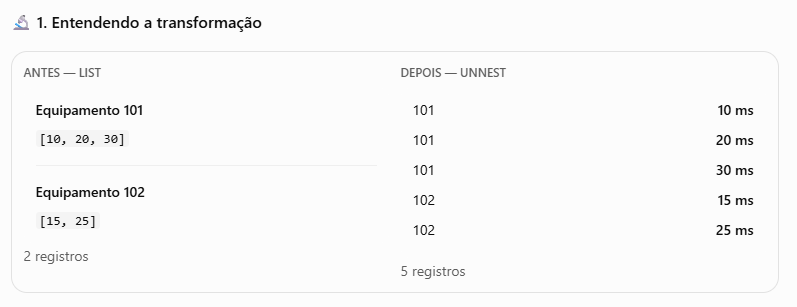

## 03.6 — Laboratório C: `MAP` para atributos variáveis

**Cenário:** diferentes equipamentos recebem etiquetas operacionais, sem exigir uma coluna para cada etiqueta.

**Hipótese:** é possível consultar um valor pela chave; uma chave ausente não deve ser interpretada como valor confirmado.

In [10]:
res_mapa = con.execute("""
WITH equipamentos_tags AS (
    SELECT
        101 AS id,
        map(
            ['prioridade', 'ambiente'],
            ['alta', 'campo']
        ) AS tags

    UNION ALL

    SELECT
        102 AS id,
        map(['prioridade'], ['normal']) AS tags
)

SELECT
    id,
    map_extract_value(tags, 'prioridade') AS prioridade,
    map_extract_value(tags, 'ambiente') AS ambiente
FROM equipamentos_tags
ORDER BY id
""").df()

display(res_mapa)

assert res_mapa['prioridade'].tolist() == ['alta', 'normal']
assert res_mapa['ambiente'].isna().sum() == 1

,id,prioridade,ambiente
0,101,alta,campo
1,102,normal,None


**Interpretação:** a ausência de `ambiente` no equipamento 102 resulta em valor nulo, não em `campo` nem em uma etiqueta inferida.

**Pontos mais importantes**

- `map([...], [...])` Constrói um mapa relacionando chaves aos respectivos valores.
- `WITH equipamentos_tags`	Cria uma CTE, ou seja, uma tabela temporária lógica para esta consulta.
- `UNION ALL`	Reúne os registros dos dois equipamentos.
- `map_extract_value(tags, 'prioridade')`	Recupera o valor associado à chave prioridade.
- `.isna().sum()`	Conta quantos valores ausentes existem na coluna do DataFrame.

**Nota:** No Pandas, o valor ausente poderá aparecer como None ou outra representação de nulo.

## 03.7 — Laboratório D: JSON nativo

**Cenário:** recebemos documentos JSON com modelos e quantidade de portas.

**Hipótese:** podemos extrair atributos nomeados e realizar conversões explícitas de tipo.

#### 🧠 1. O que é JSON?
JSON *(JavaScript Object Notation)* é um formato estruturado utilizado para trocar informações entre sistemas, APIs e aplicações.

Imagine que dois equipamentos de telecomunicações enviam seus dados assim:
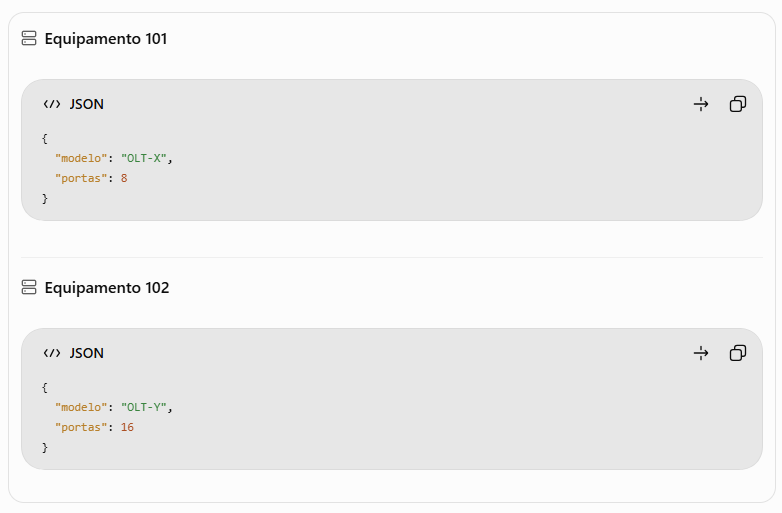    
Nosso objetivo será transformar os atributos desses documentos em colunas que podemos consultar com SQL.

In [12]:
res_json = con.execute(r"""
WITH json_equipamentos AS (
    SELECT 101 AS id, '{"modelo":"OLT-X","portas":8}'::JSON AS payload
    UNION ALL
    SELECT 102, '{"modelo":"OLT-Y","portas":16}'::JSON
)
SELECT id,
       json_extract_string(payload, '$.modelo') AS modelo,
       TRY_CAST(json_extract_string(payload, '$.portas') AS INTEGER) AS portas
FROM json_equipamentos
ORDER BY id
""").df()
display(res_json)
assert res_json['modelo'].tolist() == ['OLT-X', 'OLT-Y']
assert res_json['portas'].tolist() == [8, 16]


,id,modelo,portas
0,101,OLT-X,8
1,102,OLT-Y,16


**Interpretação:** `json_extract_string` recupera o texto; `TRY_CAST` transforma a quantidade em inteiro quando possível. Valores ausentes ou incompatíveis precisam ser investigados, pois podem produzir nulos.

**Pontos mais importantes**   


- `::JSON`	Converte o texto JSON para o tipo nativo JSON do DuckDB.
- `json_extract_string()`	Extrai um valor do documento e retorna texto.
- `$.modelo`	Caminho JSON que identifica a propriedade modelo na raiz do documento.
- `TRY_CAST(... AS INTEGER)`	Tenta converter o texto extraído para um número inteiro; se a conversão falhar, retorna NULL.
- `.df()`	Converte a consulta em um DataFrame Pandas.

**Nota:** O `TRY_CAST` devolve NULL quando não consegue converter um valor válido de entrada para o tipo solicitado. Isso permite identificar problemas de qualidade sem interromper a consulta por esse erro de conversão.

## 03.8 — Experimento controlado e desafio profissional

**Questão de negócio:** uma equipe deseja sinalizar equipamentos com média de latência acima de 19 ms.

**Antes de abrir a solução:** calcule a média das medições por equipamento; documente por que escolheu essa granularidade e como trataria uma lista vazia.

**Critérios de aceite:** uma linha por equipamento, coluna `media_latencia_ms`, validação automática e interpretação em linguagem operacional.

Imagine que você esteja monitorando equipamentos de uma rede de telecomunicações.
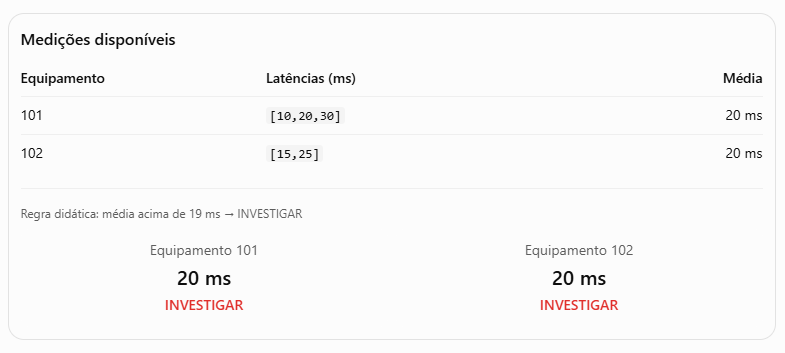    
Esse limite de 19 ms é apenas uma regra do exercício, não um SLA real.

In [13]:
# Solução de referência — execute somente após tentar
res_desafio = con.execute("""
SELECT id, local.cidade AS cidade,
       ROUND(list_avg(latencias), 2) AS media_latencia_ms,
        CASE 
           WHEN list_avg(latencias) > 19 THEN 'INVESTIGAR' 
           ELSE 'NORMAL' 
        END AS acao
FROM equipamentos ORDER BY id
""").df()
display(res_desafio)
assert res_desafio['media_latencia_ms'].tolist() == [20.0, 20.0]
assert res_desafio['acao'].tolist() == ['INVESTIGAR', 'INVESTIGAR']


,id,cidade,media_latencia_ms,acao
0,101,Campo Grande,20.0,INVESTIGAR
1,102,Dourados,20.0,INVESTIGAR


**Discussão:** ambas as médias são 20 ms; o filtro foi estritamente `>19`. Esse pequeno conjunto serve para validar lógica, não um SLA real. Para produção, seria preciso especificar janela temporal, amostragem, qualidade de sinal e regra de alerta.

**Pontos mais importantes**  

- `list_avg()` calcula a média dos valores dentro da lista de cada equipamento.
- `ROUND(..., 2)` arredonda o resultado para duas casas decimais.
- `CASE WHEN` transforma o resultado numérico em uma classificação operacional.

**o que acontece quando um equipamento não possui medições?** 

R: Se não houver medições, a média será `NULL`. No CASE atual, esse resultado acabaria classificado como NORMAL, porque a condição `NULL > 19` não é verdadeira.

Para explorar esse caso sem modificar a tabela original, podemos executar um experimento isolado:

In [14]:
teste_vazio = con.execute("""
    SELECT
        list_avg([]::INTEGER[]) AS media_latencia_ms,
        CASE
            WHEN list_avg([]::INTEGER[]) IS NULL THEN 'SEM_MEDICOES'
            WHEN list_avg([]::INTEGER[]) > 19 THEN 'INVESTIGAR'
            ELSE 'NORMAL'
        END AS acao
""").df()

display(teste_vazio)

assert teste_vazio['acao'].iloc[0] == 'SEM_MEDICOES'

,media_latencia_ms,acao
0,NaN,SEM_MEDICOES


## 03.9 — Autoavaliação (responda antes de ler o gabarito)

1. Quando `STRUCT` é mais adequado que um documento JSON arbitrário?
2. O que muda na granularidade quando usamos `UNNEST`?
3. Qual a diferença entre um `MAP` sem a chave e uma string vazia?
4. Por que converter explicitamente valores extraídos de JSON?
5. Como verificaria se um alerta de latência foi calculado por equipamento e não por amostra?

<details><summary>Gabarito comentado — abra após responder</summary>

1. Quando os campos possuem estrutura conhecida e devem ser consultados com tipos definidos.
2. Uma linha pode gerar várias observações; métricas e contagens mudam de granularidade.
3. Uma chave ausente representa ausência de valor; string vazia é um valor presente.
4. Porque dados extraídos como texto não garantem tipo numérico para cálculo.
5. Comparando contagens antes/depois, agrupamento por ID e médias calculadas manualmente nos registros de teste.

</details>


### 🧠 Gabarito comentado — Autoavaliação do Capítulo 03

#### Questão 1 — Quando STRUCT é mais adequado que JSON?

**Resposta:** `STRUCT` é mais adequado quando os atributos possuem nomes e tipos definidos, com uma estrutura conhecida e previsível.

**Exemplo:**
```sql
local.cidade
```

Nesse caso, o DuckDB acessa diretamente o atributo `cidade` de uma estrutura tipada.

**Conceito-chave:** `STRUCT` favorece estruturas conhecidas; JSON oferece flexibilidade para documentos semiestruturados.

---

#### Questão 2 — O que muda na granularidade com UNNEST?

**Resposta:** `UNNEST` transforma os elementos de uma lista em linhas individuais, alterando a granularidade da consulta.

**Exemplo:**

Antes:

| id | latencias |
|---|---|
| 101 | [10, 20, 30] |
| 102 | [15, 25] |

Depois de `UNNEST`:

| id | latencia_ms |
|---|---:|
| 101 | 10 |
| 101 | 20 |
| 101 | 30 |
| 102 | 15 |
| 102 | 25 |

**Conceito-chave:** a granularidade muda de uma linha por equipamento para uma linha por medição.

---

#### Questão 3 — MAP sem chave versus string vazia

**Resposta:** uma chave ausente representa ausência de informação; uma string vazia representa um valor existente, porém sem caracteres.

| Situação | Resultado |
|---|---|
| Chave inexistente | `NULL` |
| Chave presente com valor vazio | `''` |
| Chave presente com valor definido | `'alta'` |

**Conceito-chave:** `NULL` e string vazia não são equivalentes. Essa diferença é relevante para validações de qualidade de dados.

---

#### Questão 4 — Por que converter valores extraídos de JSON?

**Resposta:** porque atributos extraídos como texto precisam ser convertidos para tipos apropriados antes de operações numéricas e outras validações.

**Exemplo:**

```sql
TRY_CAST(
    json_extract_string(payload, '$.portas')
    AS INTEGER
) AS portas
```

- `json_extract_string()` extrai o valor como texto.
- `TRY_CAST()` tenta convertê-lo para inteiro.
- Se a conversão não for possível, retorna `NULL`.

**Conceito-chave:** extrair um valor e garantir sua tipagem são operações diferentes.

---

#### Questão 5 — Como verificar a granularidade de um alerta?

**Resposta:** confirmar que cada equipamento aparece uma única vez no resultado e que sua média foi calculada usando exclusivamente suas próprias medições.

**Exemplo:**

| Equipamento | Medições | Média | Classificação |
|---|---|---:|---|
| 101 | [10, 20, 30] | 20 ms | INVESTIGAR |
| 102 | [15, 25] | 20 ms | INVESTIGAR |

**Verificações necessárias:**

1. Conferir a quantidade de equipamentos distintos.
2. Confirmar que existe uma linha por equipamento.
3. Comparar as médias com cálculos conhecidos.
4. Verificar se o `CASE WHEN` aplica a regra à média por equipamento.

**Conceito-chave:** calcular uma média não comprova, por si só, que a granularidade está correta. É necessário validar o nível de agregação.

---

### 🎯 Síntese do aprendizado

| Tipo ou operação | Competência desenvolvida |
|---|---|
| `STRUCT` | Organizar e consultar atributos definidos |
| `LIST` | Armazenar e calcular sequências de valores |
| `UNNEST` | Expandir listas e controlar granularidade |
| `MAP` | Consultar atributos variáveis por chave |
| `JSON` | Extrair informações de documentos semiestruturados |
| `TRY_CAST` | Converter tipos e tratar falhas de conversão |
| `CASE WHEN` | Transformar métricas em classificações operacionais |

**Conclusão:** dominar os tipos aninhados exige não apenas consultar seus valores, mas também compreender tipagem, granularidade, ausência de dados e validação dos resultados.


## 03.10 — Referências, limites e publicação

- [DuckDB — Data Types](https://duckdb.org/docs/stable/sql/data_types/overview)
- [DuckDB — LIST](https://duckdb.org/docs/stable/sql/data_types/list)
- [DuckDB — STRUCT](https://duckdb.org/docs/stable/sql/data_types/struct)
- [DuckDB — MAP](https://duckdb.org/docs/stable/sql/data_types/map)
- [DuckDB — JSON](https://duckdb.org/docs/stable/data/json/overview)
- [DuckDB — UNNEST](https://duckdb.org/docs/stable/sql/query_syntax/unnest)

**Reprodução:** reinicie o kernel, execute todas as células de cima para baixo e salve as saídas esperadas. Não publique identificadores do sistema local ou dados reais.

**Status editorial:** piloto preparado; **execução integral no DuckDB não verificada neste ambiente**. Valide no kernel do projeto antes de publicar.